(sec:app-efficienza)=
# Efficienza del codice: NumPy e Numba

Il collo di bottiglia di una MD è il calcolo di energia e forze su tutte le coppie,
ripetuto a ogni passo. Questa appendice raccoglie le regole pratiche per renderlo
veloce in Python e le prove misurate sul cluster di Ag con il raccordo $P_7$. Le prove
erano la Parte 3 di [Esercizi CMS 6](../laboratori/cms6/esercizi_cms6.ipynb); le regole
vengono dal capitolo [Simulazioni MD](#sec:md-efficienza).

## 1. Vettorizzazione con NumPy

Quando possibile conviene evitare cicli espliciti su grandi array e usare operazioni
vettoriali:

```python
# meno efficiente in generale su molti elementi (dipende dal caso)
for i in range(natoms):
    for j in range(3):
        pos[i,j] = pos[i,j] + vel[i,j]*dt + 0.5*force[i,j]/mass*dt**2

# più efficiente (vettorializzato)
pos = pos + vel*dt + 0.5*force/mass*dt**2
```

Per il calcolo scalare di una singola distanza, però, l'aritmetica esplicita a 3
componenti risulta spesso più veloce di costruzioni puramente vettorializzate:

```python
dx = pos[i,0]-pos[j,0]; dy = pos[i,1]-pos[j,1]; dz = pos[i,2]-pos[j,2]
dis = (dx*dx + dy*dy + dz*dz)**0.5
```

## 2. JIT con Numba

Python è interpretato: cicli doppi su $N$ atomi sono lenti. Con
[Numba](https://numba.pydata.org/) si possono compilare *just-in-time* (JIT) le
funzioni più pesanti con il decoratore `@njit` (*nopython mode*):

```python
from numba import njit

@njit
def calc_nbrs(natoms, pos, rc, Lx, Ly, Lz, use_pbc=True):
    ...
    return nNbrs, whichNbrs

@njit
def calc_forces(natoms, pos, nNbrs, whichNbrs, coeff_poly, rp, rc, eps, sig, Lx, Ly, Lz):
    ...
    return forces
```

:::{note}
- **Prima chiamata**: compilazione (lenta). **Chiamate successive**: codice macchina
  veloce, quindi i tempi si misurano **dopo** il riscaldamento.
- **Vincoli nopython**: solo array NumPy, scalari, tuple. Per questo i **coefficienti
  del polinomio** vanno passati come argomenti, non come attributi di una classe.
- **Candidato ideale**: il doppio ciclo $N^2$ sulle coppie.
:::

Le celle seguenti preparano il sistema delle prove: una cella periodica
$4\times4\times4$ di Ag ($a=4.16$ Å, 256 atomi), LJ con il raccordo $P_7$, e le funzioni di energia, forze
e MD in versione NumPy.

In [1]:
import time

from computational_course.paths import find_project_root

ROOT = find_project_root()

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import NullFormatter, ScalarFormatter

from computational_course.fcc_lattice import fcc_supercell
from computational_course.md import assign_vel, instantaneous_T, kinetic_energy
from computational_course.poly7 import poly7  # file del corso, così come fornito

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.grid": True,
                     "grid.alpha": 0.25, "axes.axisbelow": True})

SIGMA, EPSILON, RC, RP7 = 2.644, 0.345, 4.5, 4.2  # Å, eV, Å, Å
MASS = 108.0 * 1.66e-27 / 16.0  # massa Ag in unità di codice (eV s²/Å²)
FS = 1e-15  # s
A_AG, NCELLS = 4.16, 4  # Å; 4x4x4 celle = 256 atomi
T_TH_PS, T_TOT_PS = 3.0, 13.0  # ps: termalizzazione scartata e durata delle MD

polyval, polyder = np.polynomial.polynomial.polyval, np.polynomial.polynomial.polyder
LJpoly = poly7(EPSILON, SIGMA, RC, RP7)
P7 = np.array([LJpoly.A, LJpoly.B, LJpoly.C, LJpoly.D, LJpoly.E, LJpoly.F, LJpoly.G, LJpoly.H])
dP7 = polyder(P7)


def lattice(ncells, a=A_AG):
    """Reticolo FCC `ncells`^3 (4*ncells^3 atomi) e box periodico."""
    pos, cell = fcc_supercell(a, ncells, ncells, ncells)
    return pos, np.diag(cell)


pos0, box0 = lattice(NCELLS)
print(f"N = {len(pos0)} atomi, L = {box0[0]:.2f} Å")

N = 256 atomi, L = 16.64 Å


In [2]:
def energy_forces_p7(pos, box, iu, ju, smooth=True):
    """Energia e forze LJ con taglio in RC; con smooth=True usa P7 tra RP7 e RC.

    `iu, ju` elencano ogni coppia una sola volta (j > i): l'energia non va divisa
    per 2. Restituisce anche le distanze di tutte le coppie (minima immagine).
    """
    rij = pos[iu] - pos[ju]
    rij -= box * np.round(rij / box)
    r = np.sqrt(np.einsum("ij,ij->i", rij, rij))
    inside = r < RC
    ri, rv = r[inside], rij[inside]
    sr6 = (SIGMA / ri) ** 6
    phi = 4.0 * EPSILON * (sr6**2 - sr6)
    f = 24.0 * EPSILON * (2.0 * sr6**2 - sr6) / ri  # f = -dphi/dr
    if smooth:
        tail = ri > RP7
        phi = np.where(tail, polyval(ri, P7), phi)
        f = np.where(tail, -polyval(ri, dP7), f)
    fv = (f / ri)[:, None] * rv
    force = np.zeros_like(pos)
    np.add.at(force, iu[inside], fv)
    np.add.at(force, ju[inside], -fv)
    return phi.sum(), force, r


def run_p7(pos, box, t_ini, dt_fs, smooth, *, t_tot_ps=None, seed=33282739, forze=None):
    """NVE con velocity Verlet a durata fissata; registra E_tot, T e le coppie vicine a r_c.

    La durata di default è T_TOT_PS (letta a ogni chiamata). `forze` è la funzione
    che calcola energia e forze (default: energy_forces_p7; serve alle prove con
    @jit in fondo). Se l'integrazione diverge (Δt troppo grande: E_tot non finita
    o cambiata di oltre il 50%) la simulazione si ferma e restituisce
    stabile=False, con δE/|⟨E⟩| = NaN.
    """
    forze = energy_forces_p7 if forze is None else forze
    t_tot_ps = T_TOT_PS if t_tot_ps is None else t_tot_ps
    pos = pos.copy()
    natoms = len(pos)
    iu, ju = np.triu_indices(natoms, k=1)
    vel = assign_vel(natoms, MASS, t_ini, seed=seed)
    dt = dt_fs * FS
    nsteps = int(round(t_tot_ps * 1000.0 / dt_fs))
    epot, force, r = forze(pos, box, iu, ju, smooth)
    e0 = kinetic_energy(vel, MASS) + epot
    inside_prev = r < RC
    etot, temp = np.full(nsteps, np.nan), np.full(nsteps, np.nan)
    r_in_max, r_out_min, n_window, n_cross = 0.0, np.inf, 0, 0
    stabile = True
    with np.errstate(all="ignore"):  # se diverge, overflow e NaN sono attesi
        for step in range(nsteps):
            pos += vel * dt + 0.5 * force / MASS * dt * dt
            epot, force_new, r = forze(pos, box, iu, ju, smooth)
            vel += 0.5 * (force + force_new) / MASS * dt
            force = force_new
            k = kinetic_energy(vel, MASS)
            if not np.isfinite(k + epot) or abs(k + epot - e0) > 0.5 * abs(e0):
                stabile = False
                break
            etot[step] = k + epot
            temp[step] = instantaneous_T(k, natoms)
            inside = r < RC
            r_in_max = max(r_in_max, r[inside].max())  # coppia più lontana dentro r_c
            r_out_min = min(r_out_min, r[~inside].min())  # coppia più vicina fuori r_c
            n_window += int(np.count_nonzero(inside & (r > RP7)))
            n_cross += int(
                np.count_nonzero(inside != inside_prev)
            )  # attraversamenti di r_c
            inside_prev = inside
    ith = int(round(T_TH_PS * 1000.0 / dt_fs))
    e = etot[ith:]
    return dict(
        dt_fs=dt_fs,
        stabile=stabile,
        T_mean=float(temp[ith:].mean()) if stabile else np.nan,
        E_mean=float(e.mean()) if stabile else np.nan,
        dE_rel=float(e.std() / abs(e.mean())) if stabile else np.nan,
        r_in_max=float(r_in_max),
        r_out_min=float(r_out_min),
        n_window=n_window,
        n_cross=n_cross,
        time_ps=np.arange(1, nsteps + 1) * dt_fs * 1e-3,
        etot=etot,
    )

## 3. Prove di velocità con `@njit`

**Numba** traduce una funzione Python in codice macchina la prima
volta che viene chiamata (*just-in-time*, JIT): basta il decoratore `@njit`.

Cosa sapere prima di misurare:

- `@njit` compila in modalità *nopython*: dentro la funzione si possono usare
  solo numeri, array NumPy e un sottoinsieme di funzioni NumPy, non oggetti
  come le classi o pandas. Per questo i coefficienti
  del polinomio vanno passati **come argomenti** (qui l'array `P7`), non come
  attributi della classe `poly7`.
- Le variabili globali (`SIGMA`, `RC`, ...) vengono **congelate** al momento
  della compilazione: se si cambiano dopo, la funzione compilata usa ancora i
  valori vecchi.
- La **prima chiamata** include la compilazione, che dura da decimi di secondo
  a qualche secondo. Per misurare la velocità vera si scarta la prima chiamata
  e si prende il tempo **minimo** su più ripetizioni, che è il meno disturbato
  dal resto del sistema.
- Con Numba i cicli espliciti tornano a essere veloci: si può scrivere il
  doppio ciclo sulle coppie come nello pseudocodice delle slide, senza
  vettorizzare.

## Prova 1 — lo stesso doppio ciclo in tre versioni

Energia LJ con taglio netto, sommata su tutte le coppie $i<j$ con la minima
immagine (256 atomi, 32 640 coppie):

1. **Python puro**: doppio ciclo, come nello pseudocodice;
2. **NumPy**: nessun ciclo, operazioni su array di tutte le coppie;
3. **`@njit`**: esattamente la funzione 1, compilata da Numba.

In [3]:
from numba import njit


def cronometra(f, *args, ripetizioni=5):
    """Tempo minimo di una chiamata di f(*args), in ms."""
    tempi = []
    for _ in range(ripetizioni):
        t0 = time.perf_counter()
        f(*args)
        tempi.append(time.perf_counter() - t0)
    return 1e3 * min(tempi)


def epot_python(pos, box):
    """Energia LJ (taglio netto in RC) con un doppio ciclo esplicito sulle coppie."""
    n = pos.shape[0]
    e = 0.0
    for i in range(n - 1):
        for j in range(i + 1, n):
            d2 = 0.0
            for k in range(3):
                d = pos[i, k] - pos[j, k]
                d -= box[k] * round(d / box[k])  # minima immagine
                d2 += d * d
            if d2 < RC * RC:
                sr6 = (SIGMA * SIGMA / d2) ** 3
                e += 4.0 * EPSILON * (sr6 * sr6 - sr6)
    return e


epot_numba = njit(epot_python)  # la stessa funzione, compilata


def epot_numpy(pos, box):
    """Stessa energia, vettorizzata su tutte le coppie."""
    rij = pos[IU] - pos[JU]
    rij -= box * np.round(rij / box)
    r2 = np.einsum("ij,ij->i", rij, rij)
    sr6 = (SIGMA * SIGMA / r2[r2 < RC * RC]) ** 3
    return float((4.0 * EPSILON * (sr6 * sr6 - sr6)).sum())


rng = np.random.default_rng(1)
pos_test = pos0 + 0.05 * rng.standard_normal(
    pos0.shape
)  # rompe la simmetria del reticolo
IU, JU = np.triu_indices(len(pos_test), k=1)

t0 = time.perf_counter()
e_numba = epot_numba(pos_test, box0)  # prima chiamata: compila
t_compila = time.perf_counter() - t0

e_python, e_numpy = epot_python(pos_test, box0), epot_numpy(pos_test, box0)
print(f"energie: Python {e_python:.10f}, NumPy {e_numpy:.10f}, Numba {e_numba:.10f} eV")
print(f"prima chiamata di epot_numba (compilazione inclusa): {t_compila:.2f} s\n")

t_py = cronometra(epot_python, pos_test, box0, ripetizioni=3)
t_np = cronometra(epot_numpy, pos_test, box0)
t_nb = cronometra(epot_numba, pos_test, box0)
prova1 = pd.DataFrame(
    {
        "tempo [ms]": [t_py, t_np, t_nb],
        "volte più veloce di Python": [1.0, t_py / t_np, t_py / t_nb],
    },
    index=pd.Index(["Python puro", "NumPy", "@njit"], name="versione"),
)
display(
    prova1.style.format(
        {"tempo [ms]": "{:.3f}", "volte più veloce di Python": "{:.0f}"}
    ).set_caption(f"Energia LJ su {len(IU)} coppie (tempo minimo per chiamata)")
)

energie: Python -581.7943311961, NumPy -581.7943311961, Numba -581.7943311961 eV
prima chiamata di epot_numba (compilazione inclusa): 0.24 s



,tempo [ms],volte più veloce di Python
versione,,
Python puro,69.879,1
NumPy,0.766,91
@njit,0.072,966


## Prova 2 — energia e forze con il $P_7$, al variare di $N$

La funzione che conta davvero è quella di energia e forze usata dalla MD. Qui
è riscritta come doppio ciclo con `@njit`: i coefficienti del polinomio
(`p7`, `dp7`) e i parametri entrano come argomenti, il polinomio è valutato con
lo schema di Horner. La funzione `energy_forces_p7_jit` ha la stessa interfaccia
di `energy_forces_p7`, così si possono scambiare nella MD.

Prima si controlla che le due versioni diano lo stesso risultato, poi si
misurano i tempi per $N=108$, $256$, $500$, $864$ atomi. Entrambe scorrono
tutte le $N(N-1)/2$ coppie, quindi il tempo cresce come $N^2$: la differenza
è nel prefattore.

netto: |ΔE| = 2.3e-13 eV, max |ΔF| = 2.3e-14 eV/Å, max |Δr| = 3.6e-15 Å
P7   : |ΔE| = 1.6e-06 eV, max |ΔF| = 1.3e-06 eV/Å, max |Δr| = 3.6e-15 Å


,coppie,NumPy [ms],@njit [ms],accelerazione
N,,,,
108,5778,0.24,0.020,12.3×
256,32640,1.02,0.095,10.7×
500,124750,3.54,0.323,10.9×
864,372816,10.32,0.924,11.2×


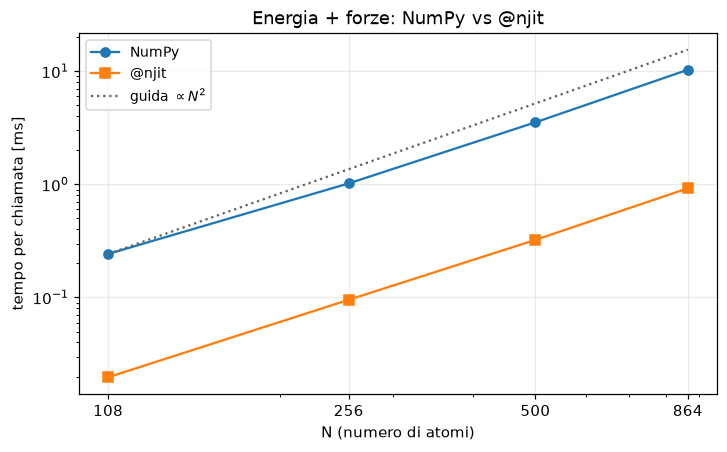

In [4]:
@njit
def _kernel_p7(pos, box, p7, dp7, sigma, eps, rp, rc, smooth):
    """Energia, forze e distanze di tutte le coppie i<j (stesso ordine di np.triu_indices)."""
    n = pos.shape[0]
    force = np.zeros_like(pos)
    r_all = np.empty(n * (n - 1) // 2)
    epot = 0.0
    rc2 = rc * rc
    m = 0  # indice della coppia
    for i in range(n - 1):
        for j in range(i + 1, n):
            dx = pos[i, 0] - pos[j, 0]
            dy = pos[i, 1] - pos[j, 1]
            dz = pos[i, 2] - pos[j, 2]
            dx -= box[0] * round(dx / box[0])  # minima immagine
            dy -= box[1] * round(dy / box[1])
            dz -= box[2] * round(dz / box[2])
            r2 = dx * dx + dy * dy + dz * dz
            r = np.sqrt(r2)
            r_all[m] = r
            m += 1
            if r2 >= rc2:
                continue
            if smooth and r > rp:
                phi = p7[7]  # Horner: P7(r) e P7'(r)
                for q in range(6, -1, -1):
                    phi = phi * r + p7[q]
                dphi = dp7[6]
                for q in range(5, -1, -1):
                    dphi = dphi * r + dp7[q]
                f = -dphi
            else:
                sr6 = (sigma * sigma / r2) ** 3
                phi = 4.0 * eps * (sr6 * sr6 - sr6)
                f = 24.0 * eps * (2.0 * sr6 * sr6 - sr6) / r
            epot += phi
            c = f / r
            force[i, 0] += c * dx
            force[i, 1] += c * dy
            force[i, 2] += c * dz
            force[j, 0] -= c * dx
            force[j, 1] -= c * dy
            force[j, 2] -= c * dz
    return epot, force, r_all


def energy_forces_p7_jit(pos, box, iu, ju, smooth=True):
    """Stessa interfaccia di energy_forces_p7 (iu, ju non servono: le coppie le scorre il ciclo)."""
    return _kernel_p7(pos, box, P7, dP7, SIGMA, EPSILON, RP7, RC, smooth)


# 1) stessi risultati? configurazione perturbata, con coppie anche nella zona del P7
pos_test = pos0 + 0.1 * rng.standard_normal(pos0.shape)
iu, ju = np.triu_indices(len(pos_test), k=1)
for smooth in (False, True):
    e_np, f_np, r_np = energy_forces_p7(pos_test, box0, iu, ju, smooth)
    e_nb, f_nb, r_nb = energy_forces_p7_jit(pos_test, box0, iu, ju, smooth)
    print(
        f"{'P7   ' if smooth else 'netto'}: |ΔE| = {abs(e_np - e_nb):.1e} eV, "
        f"max |ΔF| = {np.abs(f_np - f_nb).max():.1e} eV/Å, "
        f"max |Δr| = {np.abs(r_np - r_nb).max():.1e} Å"
    )

# 2) tempi per N crescente (la prima chiamata, qui sopra, ha già compilato)
righe = []
for ncells in (3, 4, 5, 6):
    pos_n, box_n = lattice(ncells, A_AG)
    pos_n = pos_n + 0.05 * rng.standard_normal(pos_n.shape)
    iu_n, ju_n = np.triu_indices(len(pos_n), k=1)
    t_np = cronometra(energy_forces_p7, pos_n, box_n, iu_n, ju_n, True)
    t_nb = cronometra(energy_forces_p7_jit, pos_n, box_n, iu_n, ju_n, True)
    righe.append(
        {
            "N": len(pos_n),
            "coppie": len(iu_n),
            "NumPy [ms]": t_np,
            "@njit [ms]": t_nb,
            "accelerazione": t_np / t_nb,
        }
    )
prova2 = pd.DataFrame(righe).set_index("N")
display(
    prova2.style.format(
        {
            "coppie": "{:d}",
            "NumPy [ms]": "{:.2f}",
            "@njit [ms]": "{:.3f}",
            "accelerazione": "{:.1f}×",
        }
    ).set_caption("Energia + forze con P7 (tempo minimo per chiamata)")
)

fig, ax = plt.subplots(figsize=(6.5, 4.0), constrained_layout=True)
n_arr = prova2.index.to_numpy()
ax.loglog(n_arr, prova2["NumPy [ms]"], "o-", label="NumPy")
ax.loglog(n_arr, prova2["@njit [ms]"], "s-", label="@njit")
ax.loglog(
    n_arr,
    prova2["NumPy [ms]"].iloc[0] * (n_arr / n_arr[0]) ** 2,
    ":",
    color="0.4",
    label=r"guida $\propto N^2$",
)
ax.set_xticks(n_arr)
ax.xaxis.set_major_formatter(ScalarFormatter())
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set(
    xlabel="N (numero di atomi)",
    ylabel="tempo per chiamata [ms]",
    title="Energia + forze: NumPy vs @njit",
)
ax.legend(fontsize=9)
plt.show()

## Prova 3 — una MD intera

Quanto si guadagna sull'intera simulazione? Si ripete la stessa MD
($T_\text{ini}=2500$ K, $P_7$, $\Delta t=5$ fs, 13 ps) con le due funzioni
delle forze, passate a `run_p7` con l'argomento `forze`.

In [5]:
prova3 = []
for nome, funzione in (("NumPy", energy_forces_p7), ("@njit", energy_forces_p7_jit)):
    t0 = time.perf_counter()
    res = run_p7(pos0, box0, 2500.0, 5.0, True, forze=funzione)
    prova3.append(
        {
            "versione": nome,
            "tempo MD [s]": time.perf_counter() - t0,
            "δE/|⟨E⟩|": res["dE_rel"],
            "⟨T⟩ [K]": res["T_mean"],
        }
    )
prova3 = pd.DataFrame(prova3).set_index("versione")
prova3["accelerazione"] = prova3["tempo MD [s]"].iloc[0] / prova3["tempo MD [s]"]
display(
    prova3.style.format(
        {
            "tempo MD [s]": "{:.2f}",
            "δE/|⟨E⟩|": "{:.2e}",
            "⟨T⟩ [K]": "{:.0f}",
            "accelerazione": "{:.1f}×",
        }
    ).set_caption("MD completa: T_ini = 2500 K, P7, Δt = 5 fs, 13 ps")
)

,tempo MD [s],δE/|⟨E⟩|,⟨T⟩ [K],accelerazione
versione,,,,
NumPy,2.90,3.77e-05,1277,1.0×
@njit,0.45,3.76e-05,1278,6.5×


:::{admonition} Lettura delle prove con `@jit`
:class: warning

- **Prova 1.** Il doppio ciclo in Python puro impiega circa 70 ms; NumPy circa
  0.8 ms (circa 90 volte più veloce); la stessa funzione con `@njit` circa
  0.08 ms (circa 900 volte più veloce di Python, e circa 10 volte più di NumPy).
  La compilazione alla prima chiamata dura circa 0.3 s: si ripaga già dopo
  pochi passi di MD.
- **Prova 2.** Con il taglio netto le due versioni coincidono all'errore di
  macchina ($10^{-13}$ eV). Con il $P_7$ differiscono di circa $10^{-6}$ eV:
  non è un errore, i coefficienti di `poly7.py` sono grandi e si cancellano a
  vicenda, e cambiare l'ordine delle operazioni (Horner nel ciclo, `polyval` in
  NumPy) sposta l'arrotondamento proprio a quel livello, lo stesso limite già
  visto nella cella di verifica di `poly7`. L'accelerazione è circa **10×** per
  tutte le taglie; entrambe le versioni scorrono tutte le coppie e crescono
  come $N^2$. Per fare meglio di $N^2$ servono le liste dei vicini a celle, non
  un compilatore.
- **Prova 3.** La MD intera passa da circa 3 s a circa 0.5 s: circa **6×**, meno
  del 10× della funzione delle forze, perché il resto del passo (aggiornamento
  di posizioni e velocità, diagnostica su tutte le distanze) resta in NumPy. È
  la legge di Amdahl: si accelera solo la parte compilata. $\delta E/|\langle
  E\rangle|$ coincide; ⟨T⟩ differisce di circa 1 K perché il diverso ordine
  degli arrotondamenti, in un sistema caotico, porta a traiettorie leggermente
  diverse con la stessa statistica.
:::

Con `energy_forces_p7_jit` al posto di `energy_forces_p7` (argomento `forze`
di `run_p7`) l'intera scansione della Parte 2 diventerebbe circa 6 volte più
rapida. Qui la scansione usa ancora la versione NumPy, che è quella confrontata
con il resto del capitolo.